At First, we will connect google drive to our project

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Now, we will load the dataset from drive as "dataset"

---



In [ ]:
import pandas as pd

dataset = pd.read_csv('/content/drive/MyDrive/220105_AI_ML/Task_2_Linear_&_Logistic_Regression/insurance.csv')


In the steps below, we will try to explore out dataset and understand relationships between columns.

Lets get the basic info about our dataset

In [ ]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


Lets get the basic statistical data for our dataset

In [ ]:
dataset.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


Lets view some of the data

In [ ]:
dataset.head(5)

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest,bmi_smoker,age_smoker,bmi_squared
0,19,0,27.900,0,1,16884.92400,False,False,True,27.9,19,778.410000
1,18,1,33.770,1,0,1725.55230,False,True,False,0.0,0,1140.412900
2,28,1,33.000,3,0,4449.46200,False,True,False,0.0,0,1089.000000
3,33,1,22.705,0,0,21984.47061,True,False,False,0.0,0,515.517025
4,32,1,28.880,0,0,3866.85520,True,False,False,0.0,0,834.054400


Lets see the distribution of charges.

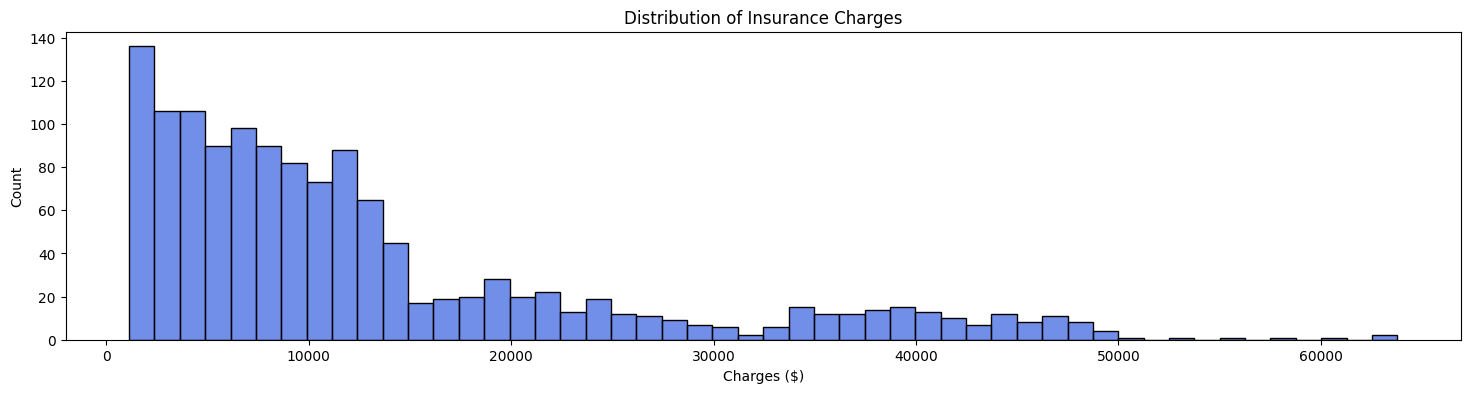

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(18,4))
sns.histplot(dataset['charges'], bins=50, color='royalblue')
plt.title('Distribution of Insurance Charges')
plt.xlabel('Charges ($)')
plt.show()

Lest see charges based on smoker vs non smoker.

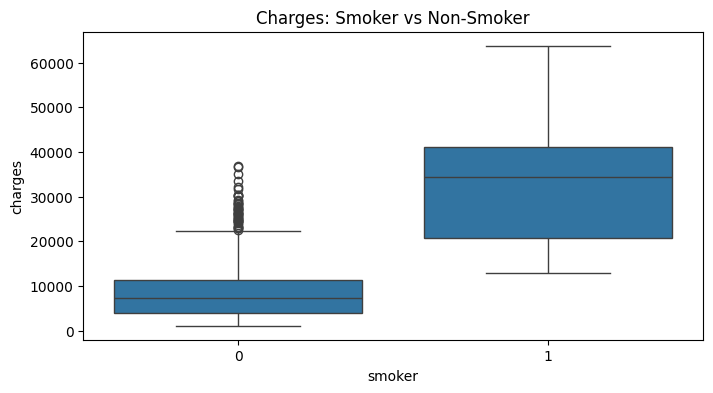

In [ ]:
plt.figure(figsize=(8,4))
sns.boxplot(x='smoker', y='charges', data=df)
plt.title('Charges: Smoker vs Non-Smoker')
plt.show()

Lets see charges by age, witth keeping smoking in mind.

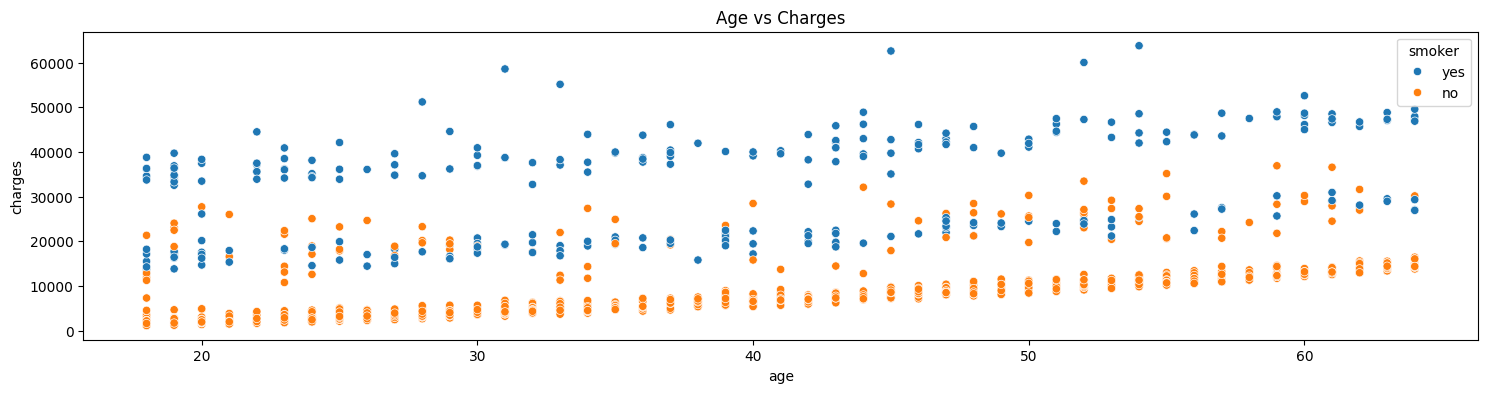

In [ ]:
plt.figure(figsize=(18,4))
sns.scatterplot(x='age', y='charges', hue='smoker', data=dataset)
plt.title('Age vs Charges')
plt.show()

Lets see charges by BMI with keeping smoking in mind

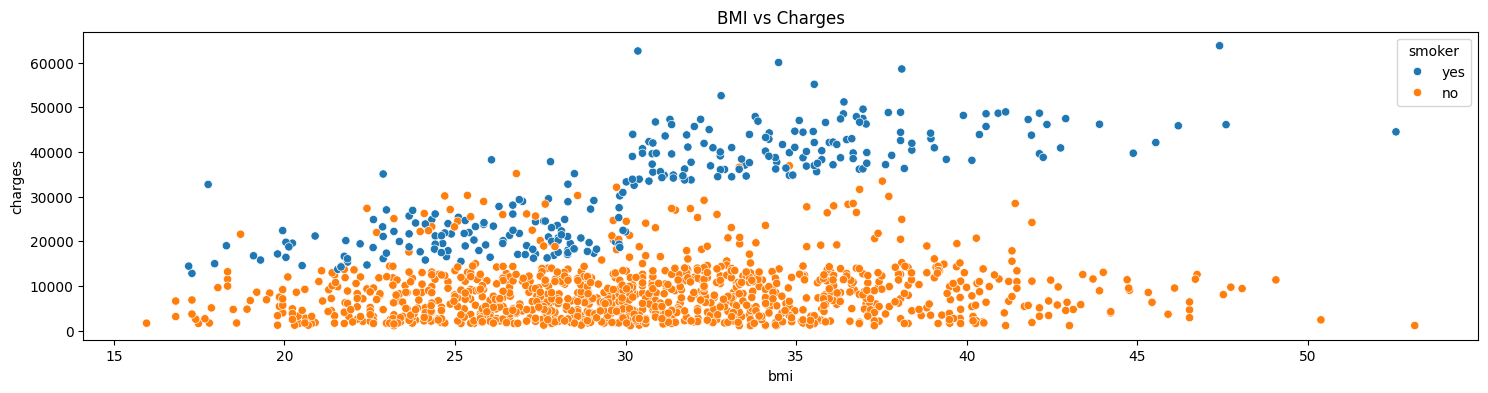

In [ ]:
plt.figure(figsize=(18,4))
sns.scatterplot(x='bmi', y='charges', hue='smoker', data=dataset)
plt.title('BMI vs Charges')
plt.show()

Lets see Charges by age with Children in mind

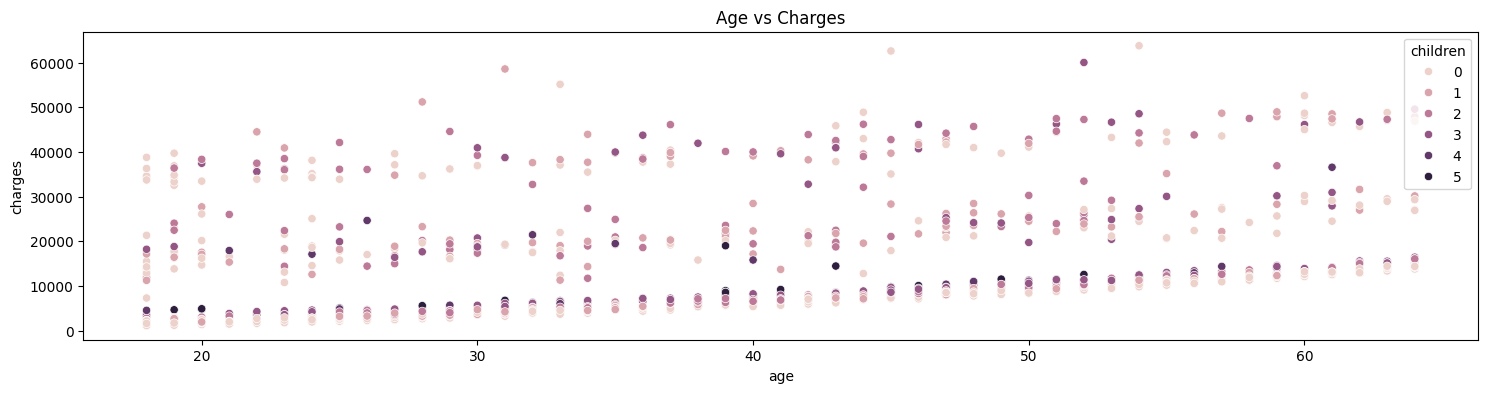

In [ ]:
plt.figure(figsize=(18,4))
sns.scatterplot(x='age', y='charges', hue='children', data=dataset)
plt.title('Age vs Charges')
plt.show()

Lets see charges by region

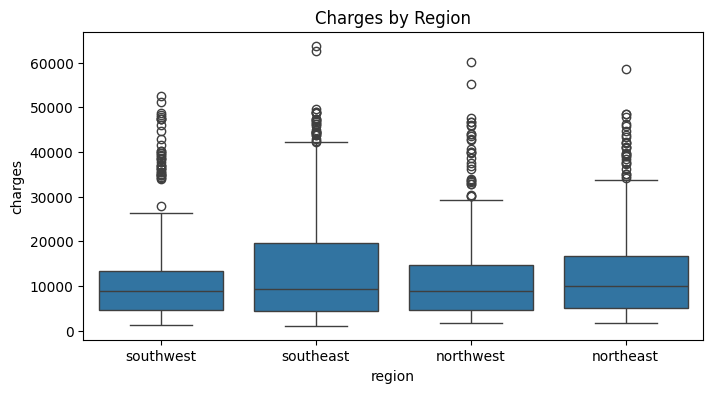

In [ ]:
plt.figure(figsize=(8,4))
sns.boxplot(x='region', y='charges', data=dataset)
plt.title('Charges by Region')
plt.show()

Now, we have to check for missing values, and then we will print some statistical data  of the columns.

In [ ]:
print(dataset.isnull().sum())

age                 0
sex                 0
bmi                 0
children            0
smoker              0
charges             0
region_northwest    0
region_southeast    0
region_southwest    0
bmi_smoker          0
age_smoker          0
bmi_squared         0
dtype: int64


Our dataset is clean, we have no null values.

Now, we will perform data preprocessing.

In [ ]:
from sklearn.preprocessing import StandardScaler

Convert categorical columns into numbers cause system only recognizes numbers

In [ ]:
dataset['sex']    = dataset['sex'].map({'male': 1, 'female': 0})
dataset['smoker'] = dataset['smoker'].map({'yes': 1, 'no': 0})
# dataset['region'] = dataset['region'].map({'southwest': 0, 'southeast': 1, 'northwest': 2, 'northeast': 3})

I have commented the region part out, cause there is a problem that the model thinks that the region with value 3 is somwhow more important the region with value 0. So we need to use binary numbers to numerize them.

In [ ]:
dataset = pd.get_dummies(dataset, columns=['region'], drop_first=True)

Lets see how each feature is related to charges using a heatmap, this heatmap can be generated only after when we converted everything to nueric value.

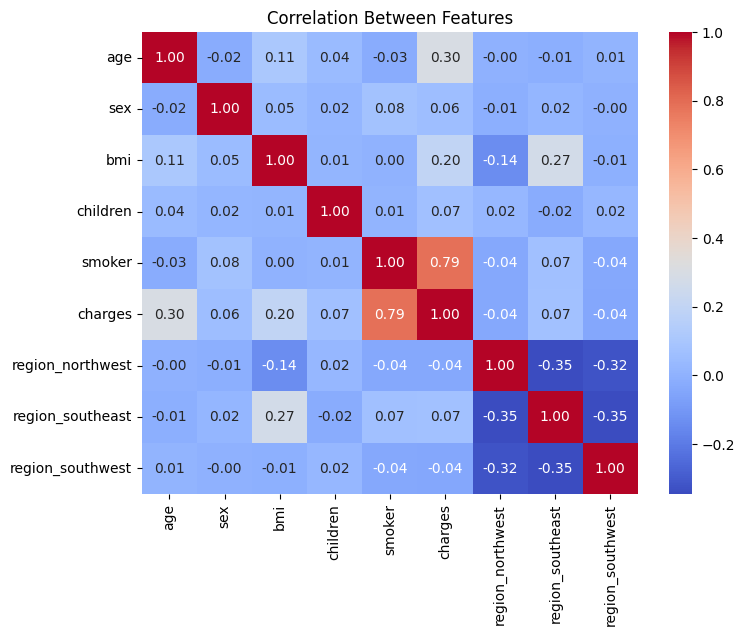

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(dataset.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Between Features')
plt.show()

Now, we will add some more columns to make our model even more accurate and better.

In [ ]:
dataset['bmi_smoker']  = dataset['bmi'] * dataset['smoker']
dataset['age_smoker']  = dataset['age'] * dataset['smoker']
dataset['bmi_squared'] = dataset['bmi'] ** 2

After adding the new columns, lets view the data

In [ ]:
dataset.describe()

,age,sex,bmi,children,smoker,charges,bmi_smoker,age_smoker,bmi_squared
count,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,0.505232,30.663397,1.094918,0.204783,13270.422265,6.288576,7.887145,977.403997
std,14.049960,0.500160,6.098187,1.205493,0.403694,12110.011237,12.721374,16.772800,387.865337
min,18.000000,0.000000,15.960000,0.000000,0.000000,1121.873900,0.000000,0.000000,254.721600
25%,27.000000,0.000000,26.296250,0.000000,0.000000,4740.287150,0.000000,0.000000,691.492881
50%,39.000000,1.000000,30.400000,1.000000,0.000000,9382.033000,0.000000,0.000000,924.160000
75%,51.000000,1.000000,34.693750,2.000000,0.000000,16639.912515,0.000000,0.000000,1203.656406
max,64.000000,1.000000,53.130000,5.000000,1.000000,63770.428010,52.580000,64.000000,2822.796900


Separate features and target, in x we will put only the features(inputs) and in y we will put the result (output)


In [ ]:
X = dataset.drop('charges', axis=1)
y = dataset['charges']

Now, we will normalize the data. In out dataset, different data has different scales. SO we normalize them to similar scale so that the model doesnt think one data is more important than any other data

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)



We should now see that our number of columns have increased.

In [ ]:
print("Preprocessing done!")
print("Features shape:", X_scaled.shape)

Preprocessing done!
Features shape: (1338, 11)


Now, we will separate the dataset into training dataset and testing dataset. we will keep 20% of the data for test.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

print("Training size:", X_train.shape)
print("Testing size: ", X_test.shape)

Training size: (1070, 11)
Testing size:  (268, 11)


Now, we will train the model

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained successfully!")
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

Model trained successfully!
Coefficients: [ 3665.39374091  -254.10318484  3403.79230325   555.68597287
 -8493.79252612  -311.38504828  -413.57882615  -545.83121314
 18621.97529591    21.97260153 -3321.0799281 ]
Intercept: 13334.926171447773


Now, we will evaluate the model to find out how good the prediction is. When I ran the model without any tweaking, the results were,  
 MAE:  $4186.51,
 MSE:  $33,635,210.43,
 RMSE: $5,799.59,
 R²:   0.7833

But after I added more custom columns and numberized the region using binaries, the results improved as below.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(X_test)

mae  = mean_absolute_error(y_test, y_pred)
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_pred)

print(f"MAE:  ${mae:,.2f}")
print(f"MSE:  ${mse:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R²:   {r2:.4f}")

MAE:  $2,732.77
MSE:  $20,637,104.26
RMSE: $4,542.81
R²:   0.8671


Now, we will plot the loss curve.

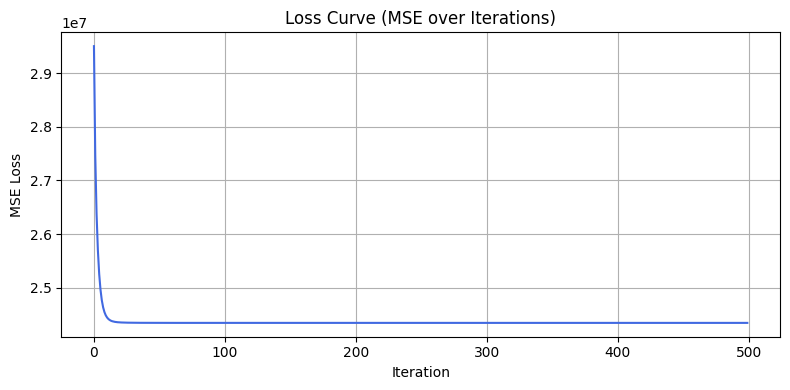

In [ ]:
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error
import warnings
warnings.filterwarnings('ignore')

losses = []
sgd_model = SGDRegressor(max_iter=1, warm_start=True, random_state=42, eta0=0.01, learning_rate='constant')

for i in range(500):
    sgd_model.fit(X_train, y_train)
    y_pred_train = sgd_model.predict(X_train)
    loss = mean_squared_error(y_train, y_pred_train)
    losses.append(loss)

plt.figure(figsize=(8, 4))
plt.plot(losses, color='royalblue')
plt.title('Loss Curve (MSE over Iterations)')
plt.xlabel('Iteration')
plt.ylabel('MSE Loss')
plt.grid(True)
plt.tight_layout()
plt.savefig('loss_curve.png', dpi=150)
plt.show()

Plot sample predictions.

        Actual  Predicted
0   9095.06825   11229.16
1   5272.17580    7646.64
2  29330.98315   33137.39
3   9301.89355   10786.58
4  33750.29180   28474.49
5   4536.25900    5677.77
6   2117.33885    2396.61
7  14210.53595   14260.96
8   3732.62510    4335.54
9  10264.44210   11840.76


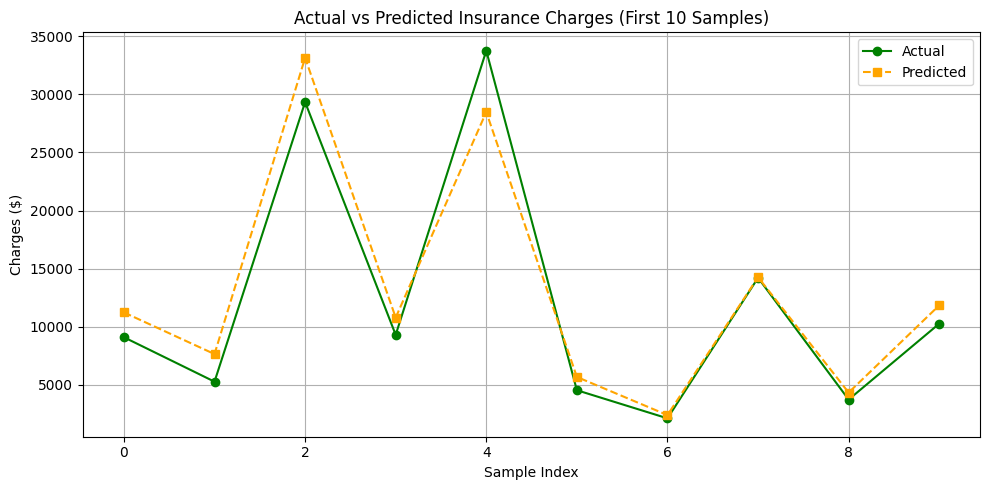

In [ ]:
comparison = pd.DataFrame({
    'Actual':    y_test.values[:10],
    'Predicted': y_pred[:10].round(2)
})

print(comparison)

plt.figure(figsize=(10, 5))
x_axis = range(10)
plt.plot(x_axis, comparison['Actual'].values,    'o-', label='Actual',    color='green')
plt.plot(x_axis, comparison['Predicted'].values, 's--', label='Predicted', color='orange')
plt.title('Actual vs Predicted Insurance Charges (First 10 Samples)')
plt.xlabel('Sample Index')
plt.ylabel('Charges ($)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('predictions.png', dpi=150)
plt.show()